=== Edge-Cloud Adaptive QoS Broker Summary ===
Total Inference Requests: 60
Local Quantized Execution Count: 26
Resolution-Scaled Offload Count: 34
Remote Cloud Execution Count: 0
Mean Inference Accuracy: 83.88%
Mean End-to-End Latency: 36.00 ms


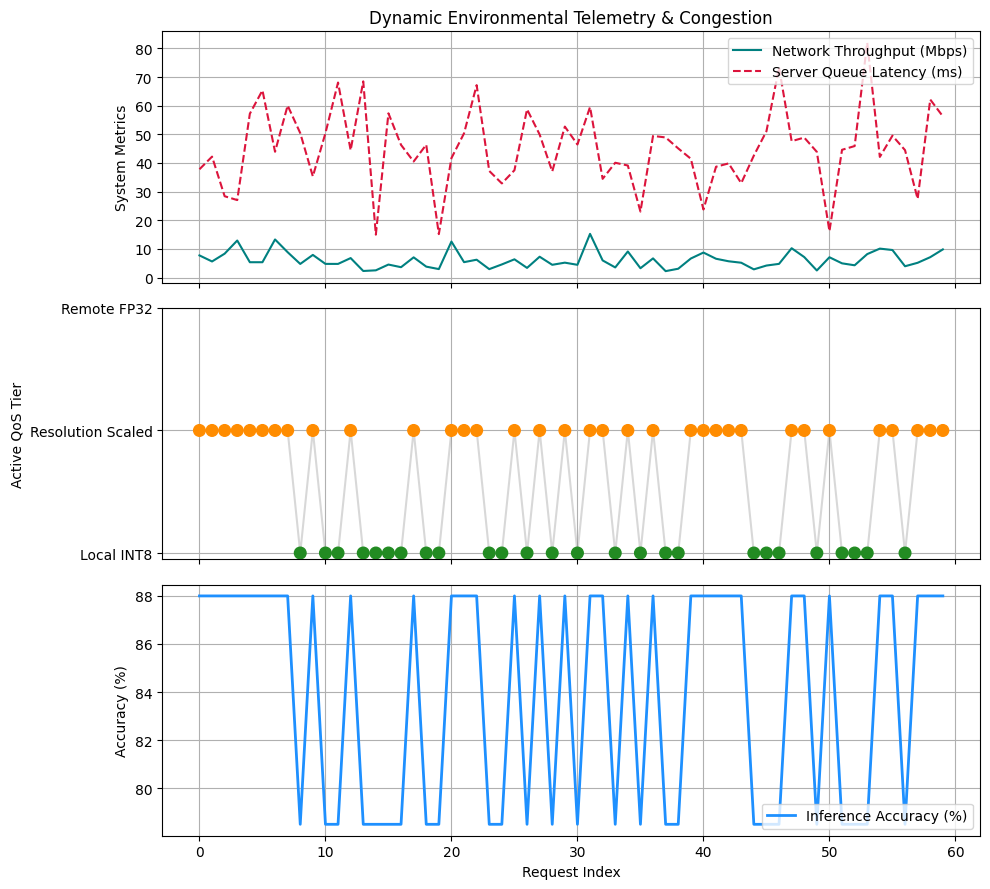

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def run_adaptive_broker_simulation():
    np.random.seed(42)
    total_steps = 60

    # Simulate network throughput (Mbps) and server queue latency (ms)
    bandwidths = np.random.lognormal(mean=1.8, sigma=0.5, size=total_steps)
    server_latencies = np.clip(np.random.normal(45.0, 15.0, total_steps), 15.0, 120.0)

    broker_modes = []         # 0: Local INT8 Quantized, 1: Resolution-Scaled Offload, 2: Remote Heavy Cloud (FP32)
    effective_accuracies = [] # Simulated accuracy percentage
    total_latencies = []      # End-to-end latency in ms

    for t in range(total_steps):
        bw = bandwidths[t]
        lat = server_latencies[t]

        # Adaptive QoS Broker Policy Logic
        if bw < 5.0 or lat > 80.0:
            # Congested network or server bottleneck -> Fallback to local quantized execution
            mode = 0
            acc = 78.5
            total_lat = 15.0 + np.random.normal(2.0, 0.5)
        elif 5.0 <= bw < 20.0:
            # Moderate network conditions -> Use resolution scaling to balance bandwidth
            mode = 1
            acc = 88.0
            total_lat = 35.0 + (50.0 / (bw + 0.1)) + (lat * 0.2)
        else:
            # Ample network capacity -> Execute full high-resolution remote cloud inference
            mode = 2
            acc = 96.5
            total_lat = 20.0 + (80.0 / (bw + 0.1)) + (lat * 0.4)

        broker_modes.append(mode)
        effective_accuracies.append(acc)
        total_latencies.append(total_lat)

    broker_modes = np.array(broker_modes)
    effective_accuracies = np.array(effective_accuracies)
    total_latencies = np.array(total_latencies)

    print("=== Edge-Cloud Adaptive QoS Broker Summary ===")
    print(f"Total Inference Requests: {total_steps}")
    print(f"Local Quantized Execution Count: {np.sum(broker_modes == 0)}")
    print(f"Resolution-Scaled Offload Count: {np.sum(broker_modes == 1)}")
    print(f"Remote Cloud Execution Count: {np.sum(broker_modes == 2)}")
    print(f"Mean Inference Accuracy: {np.mean(effective_accuracies):.2f}%")
    print(f"Mean End-to-End Latency: {np.mean(total_latencies):.2f} ms")

    # Multi-panel telemetry visualization
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

    # Top Panel: Telemetry Metrics
    ax1.plot(bandwidths, label='Network Throughput (Mbps)', color='teal')
    ax1.plot(server_latencies, label='Server Queue Latency (ms)', color='crimson', linestyle='--')
    ax1.set_title('Dynamic Environmental Telemetry & Congestion')
    ax1.set_ylabel('System Metrics')
    ax1.legend(loc='upper right')
    ax1.grid(True)

    # Middle Panel: Active QoS Tier Timeline
    colors = ['forestgreen' if m == 0 else 'darkorange' if m == 1 else 'purple' for m in broker_modes]
    ax2.scatter(range(total_steps), broker_modes, c=colors, s=70, zorder=3)
    ax2.plot(broker_modes, color='gray', alpha=0.3, zorder=2)
    ax2.set_yticks([0, 1, 2])
    ax2.set_yticklabels(['Local INT8', 'Resolution Scaled', 'Remote FP32'])
    ax2.set_ylabel('Active QoS Tier')
    ax2.grid(True)

    # Bottom Panel: Accuracy Profile
    ax3.plot(effective_accuracies, label='Inference Accuracy (%)', color='dodgerblue', linewidth=2)
    ax3.set_ylabel('Accuracy (%)')
    ax3.set_xlabel('Request Index')
    ax3.legend(loc='lower right')
    ax3.grid(True)

    plt.tight_layout()
    plt.show()

if __name__ == '__main__':
    run_adaptive_broker_simulation()